[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/okumura-kobe/kobe-data-business/blob/main/lecture04/lecture4_notebook.ipynb)

# 後期大学院演習「データで動かす社会とビジネス」
## 第4回　演習 Notebook

**テーマ：分析できるデータを作る**
― 比較の裏側にある、データ作りという仕事 ―

---

### この Notebook の使い方

- **STEP 0 はコードなし**：第2〜3回のワークシートを手元に用意し、問いと設計を確認してください
- **STEP 1〜5 でコードを実行**：`____` を自分の問いに合わせて埋めてください
- **各ステップに「なぜそうするのか」をコメントで記録**してください（課題提出に使用）
- **提出方法**：STEP 0〜5を実行し、実行結果を確認したうえで、「ファイル」→「ダウンロード」→「.ipynbをダウンロード」から保存してください。記入済みWorksheetとともにBEEF+へ提出してください。

**今日の核心**
> データを作ることは、問いを形にすることだ。
> raw data と analysis data の間には、分析者の判断が挟まっている。

**アウトプット：** analysis data（コード）＋ 各ステップの作成理由メモ

---

| | |
|---|---|
| 学籍番号 | |
| 氏名 | |
| 実施日 | |

---
## Step 0　準備

In [16]:
# ライブラリの読み込み（変更不要）
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.3f}'.format)

print('Ready')

Ready


In [17]:
# データの読み込み（変更不要）
url = "https://raw.githubusercontent.com/okumura-kobe/kobe-data-business/main/data/bike.csv"
df_raw = pd.read_csv(url)

print(f'元データ: {df_raw.shape[0]:,} 行 × {df_raw.shape[1]} 列')
df_raw.head()

元データ: 17,379 行 × 17 列


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.240,0.288,0.810,0.000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.220,0.273,0.800,0.000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.220,0.273,0.800,0.000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.240,0.288,0.750,0.000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.240,0.288,0.750,0.000,0,1,1


---
## STEP 0　出発点の確認

**コードなし。第2〜3回のワークシートを参照してください。**

以下をコメントに転記してください。

In [18]:
# 第2〜3回の設計を転記する
#
# 【修正後の問い（第2回②）】
#   平日と休日のそれぞれで、1時間あたりの利用件数（cnt）が全体平均の1.5倍を超える
#   「重点配置時間帯」はいつか。また、その時間帯の利用は登録ユーザーとカジュアルユーザーの
#   どちらが中心か（固定シフトで対応できる需要か、変わりやすい需要か）。
#
# 【目的変数（③）】
#   cnt（1時間あたりの総利用件数）。内訳として registered / casual も使う。
#
# 【比較・説明変数（④）】
#   hr（時間帯：0〜23時）、workingday（1＝平日、0＝休日・祝日）
#
# 【第3回で実施した比較】
#   1軸：groupby('hr') で cnt の平均 → 基準（全体平均189.5件の1.5倍＝約284件）を超えるのは8時・16〜19時
#   2軸：groupby(['hr', 'workingday']) → 平日は7〜8時・16〜19時、休日は11〜17時が基準を超える。
#        ピークの時間帯が平日と休日で大きくずれる。
#
# 【今日作るanalysis dataに必要な変数・加工】
#   ・分析単位：時間帯×平日休日（1行＝1組み合わせ、48行）
#   ・集約：cnt・registered・casual の平均、各組み合わせの観測件数 n_obs
#   ・変換：workingday に Weekday / Holiday のラベル
#   ・特徴量：判断基準⑦を変数にする
#       基準2 → staff_level（focus / normal / minimum）
#       基準3 → registered_share と shift_type（fixed / flexible）
#     共通実演の time_band も作る


---
## STEP 1　欠損を処理する

raw data の状態を確認し、欠損値への対応方針を決めます。

In [19]:
# 1-1　欠損値の確認
print('=== 欠損値の確認 ===')
print(df_raw.isnull().sum())
print(f'\n合計欠損数: {df_raw.isnull().sum().sum()}件')

=== 欠損値の確認 ===
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

合計欠損数: 0件


In [20]:
# 1-2　欠損処理（必要に応じて）
# bike.csv は欠損なし → 確認のみで OK

# 【なぜそうするのか】：
#   1-1で全17列の欠損が0件と確認できたため、削除も補完も行わない。
#   欠損がないのに削除・補完をすると、観測を減らしたり元にない値を作ったりして平均が歪むため。
#   raw data（df_raw）はそのまま残し、加工は作業用の df に対して行う。
#   後で加工の誤りに気づいたとき、元のデータに戻って確認できるようにするため。

df = df_raw.copy()  # raw dataを保持しつつ、以降はdfを加工する
print(f'処理後: {df.shape[0]:,} 行 × {df.shape[1]} 列')

# 補足：欠損はないが、時間帯ごとの観測件数にはわずかな差がある（3・4時が少ない）
print('\n時間帯別の観測件数（最小・最大）:', df.groupby('hr').size().min(), '〜', df.groupby('hr').size().max())

処理後: 17,379 行 × 17 列

時間帯別の観測件数（最小・最大）: 697 〜 730


---
## STEP 2　分析単位を作る

自分の問いに必要な粒度でデータを集計します。
**「1行が何を表すanalysis dataにするか」を先に決めてください。**

ワークシート STEP 2「分析単位の設計」を参照してください。

> **共通実演と自由演習**：共通実演では、教員の実演と同じく、`hr`（時間帯）× `workingday`（平日休日）を集計キーとし、`cnt`・`registered`・`casual` の平均を計算します（第3回と同じ粒度）。自由演習では、自分の問いに応じて別のキー・変数（例：季節別・天候別）を選んで構いません。その場合、STEP 3〜5の共通実演は、自分の変数に読み替えてください。

In [21]:
# 2-1　分析単位の設計（コメントに書く）
#
# 【1行が表す単位】：
#   時間帯（0〜23時）× 平日／休日 の1組み合わせ（24×2＝48行）。
#   1行は「平日の8時」のような、配置を決める1つの時間枠を表す。
#
# 【groupbyのキー】：
#   hr、workingday
#
# 【集計する変数と方法】：
#   cnt・registered・casual の mean（平均）
#
# 【なぜその粒度にするのか】：
#   ・意思決定は「平日と休日それぞれで、どの時間帯にスタッフを厚くするか」であり、
#     シフトは時間単位で組むため、時間帯×平日休日が判断の単位にそのまま対応する。
#   ・sum ではなく mean：観測の約68%が平日で日数が違う。合計だと日数の多い平日が大きく見えるため、
#     1時間あたりの需要の大きさを比べられる平均を使う。
#   ・registered / casual も残す：判断基準3（登録ユーザー8割以上なら固定シフト）の判定に必要。
#   ・weathersit はキーに入れない：天候は当日の予報で調整する変数と位置づけたため。
#     入れると48×4＝192組になり、大雨・雪は観測がごく少なく平均が不安定になる。

# 2-2　groupbyで集計する
df_agg = df.groupby(['hr', 'workingday'])[['cnt', 'registered', 'casual']].mean().reset_index()

print(f'集計後: {df_agg.shape[0]} 行 × {df_agg.shape[1]} 列')
df_agg.head(10)

集計後: 48 行 × 5 列


,hr,workingday,cnt,registered,casual
0,0,0,90.800,74.152,16.648
1,0,1,36.786,29.637,7.149
2,1,0,69.509,57.004,12.504
3,1,1,16.553,12.842,3.711
4,2,0,53.171,42.772,10.399
5,2,1,8.684,6.546,2.138
6,3,0,25.775,19.322,6.454
7,3,1,4.943,4.032,0.911
8,4,0,8.264,6.000,2.264
9,4,1,5.430,4.664,0.766


---
## STEP 3　変数を整える

比較に必要な変数を追加・整理します。
型の変換、値のラベル付けなど、第3回の比較分析を再現できる形に整えます。

**共通実演：** `workingday`（1＝平日、0＝休日）の数値コードに、意味のあるラベル（`Weekday` / `Holiday`）を付けます。

> 数値コードに**ラベルを付ける**処理（今回）と、カテゴリを 0/1 の列に展開する**ダミー変数を作る**処理は、別の操作です。
> `workingday` を category 型に変換することは必須ではなく、必要に応じて行う発展的な操作です。

In [22]:
# 3-1　カテゴリ変換・値の整理

# ---- 共通実演：数値コードにラベルを付ける ----
if 'workingday' in df_agg.columns:
    df_agg['workingday_label'] = df_agg['workingday'].map({1: 'Weekday', 0: 'Holiday'})
    print('workingday_label の値:')
    print(df_agg['workingday_label'].value_counts())
else:
    print('df_agg に workingday 列がないため、共通実演（workingday_label）は省略します。')
    print('自分の問いに必要な変換は、下の「自由演習」に書いてください。')

# 【なぜそうするのか】：
#   1/0 のままでは、表やグラフを見た人がどちらが平日か分からない。
#   意思決定者に見せる結果にそのまま使える言葉にするため。
#   元の workingday 列は計算用（0/1）として残す。

# ---- 自由演習：自分の問いに必要な変換 ----
# (1) カテゴリ型にして並び順を Weekday → Holiday に固定する
#   【理由】文字列のままだとアルファベット順で Holiday が先に並び、第3回の表（平日→休日）と比べにくいため。
df_agg['workingday_label'] = pd.Categorical(df_agg['workingday_label'],
                                            categories=['Weekday', 'Holiday'])

# (2) 各組み合わせの観測件数 n_obs を結合する（merge）
#   【理由】平均の裏にある件数を残すため。件数の少ない組み合わせの平均は不安定であり、
#          STEP 5 で集約後の平均をさらに平均するとき、件数で重み付けして元データと照合するのに使う。
n_obs = df.groupby(['hr', 'workingday']).size().reset_index(name='n_obs')
df_agg = df_agg.merge(n_obs, on=['hr', 'workingday'], how='left')

print()
print('変換後の列と型:')
print(df_agg.dtypes)

workingday_label の値:
workingday_label
Holiday    24
Weekday    24
Name: count, dtype: int64

変換後の列と型:
hr                     int64
workingday             int64
cnt                  float64
registered           float64
casual               float64
workingday_label    category
n_obs                  int64
dtype: object


---
## STEP 4　特徴量を作る

問いに答えるために新しい変数を作ります。
**自分の問いに必要な特徴量を1つ以上作成してください。**

ワークシート STEP 4「4-2　特徴量作成のポイント」を参照してください。
> 例：「通勤時間帯か否か」を表すフラグ変数 `rush_hour` は、
> 「時間帯による需要の違いを見る」という問いに直接対応する。

**共通実演と自由演習**

- **4-1（共通実演）**：時間帯 `hr` を、運営企画の言葉に翻訳した特徴量 `time_band` を作ります。
- **4-2（自由演習）**：自分の問い（第2・3回）に必要な特徴量を、**別に1つ以上**設計して作ります。`time_band` を作っただけでは、自分の特徴量を設計したことにはなりません。

| `time_band` | 定義（`hr`） | 講義PPTでの呼称 |
|---|---|---|
| `morning_peak` | 6時以上10時未満 | 朝ピーク |
| `daytime` | 10時以上16時未満 | 日中 |
| `evening_peak` | 16時以上20時未満 | 夕方ピーク |
| `night` | 上記以外 | 夜間 |

In [23]:
# 4-1　共通実演：時間帯の特徴量 time_band
def time_band(hr):
    if 6 <= hr < 10:
        return 'morning_peak'
    elif 10 <= hr < 16:
        return 'daytime'
    elif 16 <= hr < 20:
        return 'evening_peak'
    else:
        return 'night'

# 表示順（時間の流れの順）を固定するため、順序付きカテゴリにする
band_order = ['morning_peak', 'daytime', 'evening_peak', 'night']

if 'hr' in df_agg.columns:
    df_agg['time_band'] = pd.Categorical(
        df_agg['hr'].apply(time_band), categories=band_order, ordered=True
    )
else:
    print('df_agg に hr 列がないため、共通実演（time_band）は省略します。')

# ---- 4-2　自由演習：自分の問いに必要な特徴量 ----
#
# 【変数1】staff_level（配置レベル）
# 【定義・コード】元データ df の全体平均を基準値とし、
#     cnt ≥ 基準値×1.5 → 'focus'（重点配置）、cnt < 基準値×0.5 → 'minimum'（最小限）、それ以外 → 'normal'
# 【なぜこの変数が問いに必要か】
#     判断基準⑦の基準2を、各時間枠に直接付けた変数。「重点配置時間帯はいつか」に行ごとに答えられる。
#     time_band は時刻で機械的に区切るため平日と休日に同じ区切りを当てることになり、
#     休日の昼のピーク（11〜17時）をうまく表せない。staff_level は需要水準から決まるので、
#     平日と休日で別々の重点時間帯を表せる。
#     ※基準値は df_agg ではなく df の平均を使う。48組の平均をそのまま平均すると、
#       平日・休日の観測件数の違いが反映されず、元の全体平均とずれるため（STEP 5で確認）。
#
# 【変数2】registered_share（登録ユーザー比率）
# 【定義・コード】registered / cnt（0〜1）
# 【なぜこの変数が問いに必要か】
#     問いの後半「その時間帯の利用は登録ユーザーとカジュアルユーザーのどちらが中心か」に答える。
#     件数のままでは時間帯ごとに規模が違って比べにくいため比率にした。
#
# 【変数3】shift_type（シフトの型）
# 【定義・コード】registered_share ≥ 0.8 → 'fixed'（固定シフト）、それ以外 → 'flexible'（柔軟シフト）
# 【なぜこの変数が問いに必要か】
#     判断基準⑦の基準3を変数にしたもの。登録ユーザー中心の需要は毎日同じ時間に起きて予測しやすく、
#     カジュアル中心の需要は変わりやすい。staff_level と組み合わせると、各時間枠の配置方針を1行で読める。

threshold = df['cnt'].mean()          # 元データの全体平均（1時間あたり）
focus_line = threshold * 1.5          # 重点配置の基準（判断基準2）
minimum_line = threshold * 0.5        # 最小限にする基準（判断基準2）
print(f'全体平均: {threshold:.1f}　重点配置の基準(1.5倍): {focus_line:.1f}　最小限の基準(0.5倍): {minimum_line:.1f}')

def staff_level(cnt):
    if cnt >= focus_line:
        return 'focus'
    elif cnt < minimum_line:
        return 'minimum'
    else:
        return 'normal'

df_agg['staff_level'] = pd.Categorical(
    df_agg['cnt'].apply(staff_level), categories=['focus', 'normal', 'minimum'], ordered=True
)
df_agg['registered_share'] = df_agg['registered'] / df_agg['cnt']
df_agg['shift_type'] = np.where(df_agg['registered_share'] >= 0.8, 'fixed', 'flexible')

print('特徴量作成後の列:')
print(df_agg.columns.tolist())
df_agg.head()

全体平均: 189.5　重点配置の基準(1.5倍): 284.2　最小限の基準(0.5倍): 94.7
特徴量作成後の列:
['hr', 'workingday', 'cnt', 'registered', 'casual', 'workingday_label', 'n_obs', 'time_band', 'staff_level', 'registered_share', 'shift_type']


,hr,workingday,cnt,registered,casual,workingday_label,n_obs,time_band,staff_level,registered_share,shift_type
0,0,0,90.800,74.152,16.648,Holiday,230,night,minimum,0.817,fixed
1,0,1,36.786,29.637,7.149,Weekday,496,night,minimum,0.806,fixed
2,1,0,69.509,57.004,12.504,Holiday,230,night,minimum,0.820,fixed
3,1,1,16.553,12.842,3.711,Weekday,494,night,minimum,0.776,flexible
4,2,0,53.171,42.772,10.399,Holiday,228,night,minimum,0.804,fixed


---
## STEP 5　作った analysis data を確認する

**完成 ≠ 正しい。確認して初めて完成です。**

ワークシート STEP 5 のチェックリストに沿って確認し、結果を記録してください。

**確認の対象**：STEP 2〜4で作った `df_agg`（集約後のanalysis data）です。`df` は記録単位の元データで、ここでの確認対象ではありません。

In [24]:
# 5-1　基本確認（確認対象：df_agg ＝ 集約後のanalysis data）

print('=== ① 行数・列数（shape）===')
print(df_agg.shape)

print('\n=== ② 欠損値（isnull）===')
print(df_agg.isnull().sum())

print('\n=== ③ 変数の型（dtypes）===')
print(df_agg.dtypes)

print('\n=== ④ 値の範囲（describe）===')
print(df_agg.describe().round(2))

# 【確認】describe の cnt の平均は、元データの全体平均と一致するか？
print('\n=== 平均の照合 ===')
print(f'df_agg の cnt を単純平均        : {df_agg["cnt"].mean():.2f}')
print(f'df_agg の cnt を n_obs で重み付け: {np.average(df_agg["cnt"], weights=df_agg["n_obs"]):.2f}')
print(f'元データ df の cnt の平均        : {df["cnt"].mean():.2f}')
# 単純平均は平日・休日の件数の違いを反映しないためずれる。重み付けすると元データと一致する。
# → 判断基準の基準値は df の平均から計算する（STEP 4 で対応済み）。

=== ① 行数・列数（shape）===
(48, 11)

=== ② 欠損値（isnull）===
hr                  0
workingday          0
cnt                 0
registered          0
casual              0
workingday_label    0
n_obs               0
time_band           0
staff_level         0
registered_share    0
shift_type          0
dtype: int64

=== ③ 変数の型（dtypes）===
hr                     int64
workingday             int64
cnt                  float64
registered           float64
casual               float64
workingday_label    category
n_obs                  int64
time_band           category
staff_level         category
registered_share     float64
shift_type            object
dtype: object

=== ④ 値の範囲（describe）===
          hr  workingday     cnt  registered  casual   n_obs  registered_share
count 48.000      48.000  48.000      48.000  48.000  48.000            48.000
mean  11.500       0.500 186.370     145.070  41.300 362.060             0.790
std    7.000       0.510 142.580     116.550  41.280 133.830             0

In [25]:
# 5-2　新しく作った変数の確認
my_features = ['staff_level', 'registered_share', 'shift_type']

common_features = ['workingday_label', 'time_band']

print('=== ⑤ 新変数の値確認 ===')
for c in common_features + my_features:
    if c in df_agg.columns:
        print(f'--- {c} ---')
        if c == 'registered_share':
            print(df_agg[c].describe().round(3))   # 連続値なので範囲を確認
        else:
            print(df_agg[c].value_counts().sort_index().head(20))
        print()
    else:
        print(f'--- {c} --- df_agg にありません（作成していない場合は、この表示で問題ありません）')
        print()

# staff_level が平日・休日でどう分かれたか
print('=== staff_level × 平日休日（時間枠の数）===')
print(pd.crosstab(df_agg['staff_level'], df_agg['workingday_label']))

=== ⑤ 新変数の値確認 ===
--- workingday_label ---
workingday_label
Weekday    24
Holiday    24
Name: count, dtype: int64

--- time_band ---
time_band
morning_peak     8
daytime         12
evening_peak     8
night           20
Name: count, dtype: int64

--- staff_level ---
staff_level
focus      13
normal     19
minimum    16
Name: count, dtype: int64

--- registered_share ---
count   48.000
mean     0.787
std      0.090
min      0.617
25%      0.736
50%      0.790
75%      0.852
max      0.958
Name: registered_share, dtype: float64

--- shift_type ---
shift_type
fixed       22
flexible    26
Name: count, dtype: int64

=== staff_level × 平日休日（時間枠の数）===
workingday_label  Weekday  Holiday
staff_level                       
focus                   6        7
normal                 11        8
minimum                 7        9


In [26]:
# 5-3　第3回の比較を再現できるか確認する
# 【注意】集約済みの平均値をさらに平均する場合、各グループの観測件数が異なると、
#        元データから直接計算した平均とは一致しないことがある。

print('=== ⑥ 第3回の比較の再現（時間帯 × 平日休日）===')
try:
    pivot_hr = df_agg.pivot_table(
        index='hr',
        columns='workingday_label',
        values='cnt',
        aggfunc='mean'
    ).round(1)
    print(pivot_hr)
except KeyError as e:
    print(f'df_agg にない列名が指定されました: {e}')
    print('→ STEP 2〜4 で作った列名（df_agg.columns）を確認してください')

print()
print('=== 第4回で作った特徴量による再整理 ===')
try:
    pivot_band = df_agg.pivot_table(
        index='time_band',
        columns='workingday_label',
        values='cnt',
        aggfunc='mean'
    ).round(1)
    print(pivot_band)
except KeyError as e:
    print(f'df_agg にない列名が指定されました: {e}')
    print('→ STEP 2〜4 で作った列名（df_agg.columns）を確認してください')

print()
print('※ 集約済みの平均値をさらに平均する場合、各グループの観測件数が異なると、')
print('   元データから直接計算した平均とは一致しないことがある。')

=== ⑥ 第3回の比較の再現（時間帯 × 平日休日）===
workingday_label  Weekday  Holiday
hr                                
0                  36.800   90.800
1                  16.600   69.500
2                   8.700   53.200
3                   4.900   25.800
4                   5.400    8.300
5                  24.900    8.700
6                 102.500   18.700
7                 290.600   43.400
8                 477.000  105.700
9                 241.500  171.600
10                135.400  255.900
11                158.200  315.300
12                200.800  366.300
13                198.400  372.700
14                183.600  364.600
15                201.300  358.800
16                293.100  352.700
17                525.300  323.500
18                492.200  281.100
19                348.400  231.700
20                249.700  174.700
21                186.300  142.100
22                138.400  116.100
23                 88.700   85.900

=== 第4回で作った特徴量による再整理 ===
workingday_label  Weekday  Holida

In [27]:
# 5-4　自分の特徴量で問いに答える：平日・休日別の配置表
# 1行＝1時間帯、列＝平日／休日。各セルは「配置レベル／シフトの型」
df_agg['plan'] = df_agg['staff_level'].astype(str) + ' / ' + df_agg['shift_type']
schedule = df_agg.pivot(index='hr', columns='workingday_label', values='plan')
print('=== 平日・休日別の配置表（staff_level / shift_type）===')
print(schedule)

print('\n=== 重点配置（focus）の時間枠と登録ユーザー比率 ===')
focus = df_agg[df_agg['staff_level'] == 'focus'][['workingday_label', 'hr', 'cnt', 'registered_share', 'shift_type']]
print(focus.sort_values(['workingday_label', 'hr']).round(2).to_string(index=False))

df_agg = df_agg.drop(columns='plan')  # 表示用の列なので analysis data からは外す

=== 平日・休日別の配置表（staff_level / shift_type）===
workingday_label             Weekday             Holiday
hr                                                      
0                    minimum / fixed     minimum / fixed
1                 minimum / flexible     minimum / fixed
2                 minimum / flexible     minimum / fixed
3                    minimum / fixed  minimum / flexible
4                    minimum / fixed  minimum / flexible
5                    minimum / fixed     minimum / fixed
6                     normal / fixed  minimum / flexible
7                      focus / fixed     minimum / fixed
8                      focus / fixed      normal / fixed
9                     normal / fixed   normal / flexible
10                 normal / flexible   normal / flexible
11                 normal / flexible    focus / flexible
12                 normal / flexible    focus / flexible
13                 normal / flexible    focus / flexible
14                 normal / flexible    focu

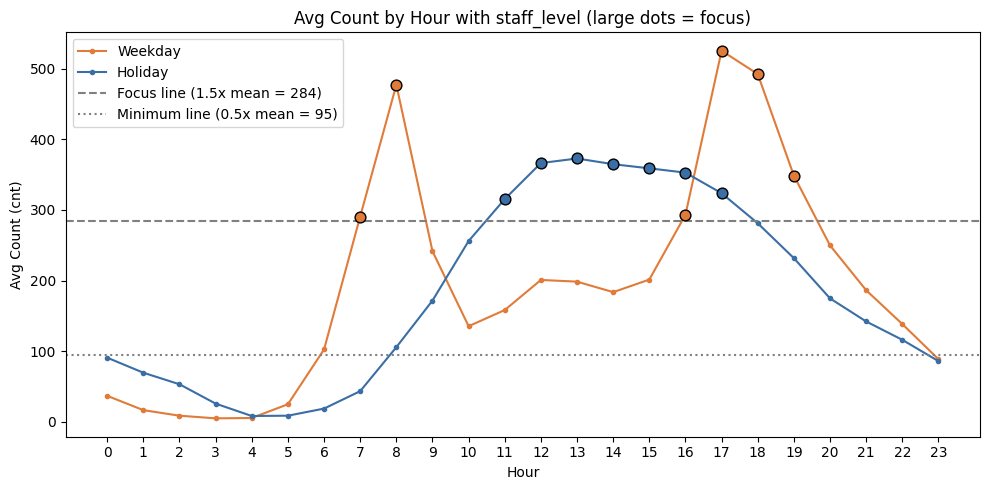

In [28]:
# 5-5　可視化で確認：基準線と重点配置の時間枠
fig, ax = plt.subplots(figsize=(10, 5))
colors = {'Weekday': '#E07B39', 'Holiday': '#3A6EA5'}
for label in ['Weekday', 'Holiday']:
    sub = df_agg[df_agg['workingday_label'] == label].sort_values('hr')
    ax.plot(sub['hr'], sub['cnt'], marker='o', markersize=3, color=colors[label], label=label)
    f = sub[sub['staff_level'] == 'focus']
    ax.scatter(f['hr'], f['cnt'], s=60, color=colors[label], edgecolor='black', zorder=3)
ax.axhline(focus_line, color='gray', linestyle='--', label=f'Focus line (1.5x mean = {focus_line:.0f})')
ax.axhline(minimum_line, color='gray', linestyle=':', label=f'Minimum line (0.5x mean = {minimum_line:.0f})')
ax.set_xticks(range(24))
ax.set_title('Avg Count by Hour with staff_level (large dots = focus)')
ax.set_xlabel('Hour')
ax.set_ylabel('Avg Count (cnt)')
ax.legend()
plt.tight_layout()
plt.show()

In [29]:
# 完成したanalysis dataの最終確認
print('=== 完成した analysis data ===')
print(f'形状: {df_agg.shape}')
print(f'列名: {df_agg.columns.tolist()}')
print()
print(df_agg.head(10))

=== 完成した analysis data ===
形状: (48, 11)
列名: ['hr', 'workingday', 'cnt', 'registered', 'casual', 'workingday_label', 'n_obs', 'time_band', 'staff_level', 'registered_share', 'shift_type']

   hr  workingday    cnt  registered  casual workingday_label  n_obs  \
0   0           0 90.800      74.152  16.648          Holiday    230   
1   0           1 36.786      29.637   7.149          Weekday    496   
2   1           0 69.509      57.004  12.504          Holiday    230   
3   1           1 16.553      12.842   3.711          Weekday    494   
4   2           0 53.171      42.772  10.399          Holiday    228   
5   2           1  8.684       6.546   2.138          Weekday    487   
6   3           0 25.775      19.322   6.454          Holiday    227   
7   3           1  4.943       4.032   0.911          Weekday    470   
8   4           0  8.264       6.000   2.264          Holiday    227   
9   4           1  5.430       4.664   0.766          Weekday    470   

  time_band staff_l

---
## まとめ

### 今日作ったもの

| 項目 | 内容 |
|---|---|
| 分析単位 | 時間帯（0〜23時）× 平日／休日 の1組み合わせ（1行＝配置を決める1つの時間枠） |
| 行数 | 48行（24時間 × 2区分）、11列 |
| 主要な変数 | hr、workingday（workingday_label）、cnt・registered・casual の平均、n_obs |
| 作成した特徴量 | 共通実演：time_band ／ 独自：staff_level（判断基準2）、registered_share、shift_type（判断基準3） |

### 今日の核心

> **データを作ることは、問いを形にすることだ。**
> raw data と analysis data の間には、分析者の判断が挟まっている。
> データ作成は前処理ではなく、分析設計そのものである。

---

### 提出物について

今回で第2〜4回の小プロジェクトが完了しました。

第4回の提出物は、実行結果を保存したNotebook（.ipynb）と、記入済みWorksheet（.docx）の2点です。11月17日（火）23:59までにBEEF+へ提出してください。

---

### 次回（第5回）：信用リスク分析ケースへ

第5回から新しいケース（信用リスク分析）に入ります。
第2〜4回で学んだ「問いを立てる → 比較する → データを作る」の考え方を引き継ぎます。